# Sagert EOS: Neutron Star Computational Implementation

This notebook develops the computational implementation of the physics explored in `sagert_neutron_star_physics.ipynb`, following Sagert et al., *Compact Stars for Undergraduates*.

## Aim

To translate the physical equations developed in the accompanying physics notebook into Python, building and testing the numerical methods required to investigate neutron star equations of state and stellar structure.

### Numerical verification

Numerical calculations will be checked against the corresponding analytical expressions, limiting behaviour and results presented in Sagert et al., where applicable.

Discrepancies, numerical limitations and assumptions will be investigated and documented throughout development.

In [1]:
# Import the libraries

from scipy import constants  
import numpy as np               
import matplotlib.pyplot as plt 
from scipy.integrate import solve_ivp       

In [2]:
# Define the physical constants in SI units

hbar = constants.hbar                # Reduced Planck constant, J s
pi = constants.pi                    # pi
m_n = constants.m_n                  # Neutron mass, kg
c = constants.c                      # Speed of light, m/s
G = constants.G                      # Gravitational constant, N m**2/kg**2
M_sun = 1.98847e30                   # solar mass in kg 


In [3]:
# Calculate the neutron polytropic constant using Sagert Eq. (73)

k_nrel = hbar**2/(15*pi**2*m_n)*(3*pi**2/(m_n*c**2))**(5/3)

In [4]:
# Define the nonrelativistic polytropic exponent from Sagert Eq. (72)

gamma = 5/3


In [5]:
# Define the neutron degeneracy pressure using Sagert Eq. (72)
# Converts energy density (J/m^3) into pressure (Pa)

def non_relativistic_pressure(epsilon):
    return k_nrel*epsilon**gamma

In [6]:
# Invert the polytropic EOS to calculate energy density from pressure
# Sagert Eq. (72)
# p: pressure in Pa
# k_nrel: polytropic constant
# gamma: polytropic exponent
# Returns energy density in J/m^3

def polytropic_energy_density(p, k_nrel, gamma):
    return (p/k_nrel)**(1/gamma)

In [7]:
# Define a test energy density in SI units
# Used to verify the neutron polytropic EOS

epsilon = 1e33

In [8]:
# Calculate the pressure from the test energy density
# Uses the nonrelativistic neutron EOS from Sagert Eq. (72)

p = non_relativistic_pressure(epsilon)

In [9]:
# Recover energy density from the calculated pressure
# Checks that the forward and inverse EOS give consistent results

polytropic_energy_density(p, k_nrel, gamma)

1.0000000000000005e+33

In [10]:
# Calculate the rate of change of enclosed mass using Sagert Eq. (7)
# Determines how much mass is added as we move outwards through the star
# r: radius in metres
# epsilon: energy density in J/m^3
# Returns dm/dr in kg/m

def mass_gradient(r, epsilon):
    return 4*pi*r**2*epsilon/c**2

In [11]:
# Calculate the Newtonian pressure gradient using Sagert Eq. (8)
# Determines how pressure changes with radius under gravity
# r: radius in metres
# epsilon: energy density in J/m^3
# m: enclosed mass in kg
# Returns dp/dr in Pa/m

def pressure_gradient(r, epsilon, m):
    return -G*epsilon*m/(c**2*r**2)

In [12]:
# Combine Sagert Eqs. (7) and (8) using the polytropic EOS
# Calculates the mass and pressure gradients needed by the numerical solver
# y: current state [m, p], containing enclosed mass (kg) and pressure (Pa)

def stellar_structure(r, y, k_nrel, gamma):
    m, p = y

    epsilon = polytropic_energy_density(max(p, 0.0), k_nrel, gamma)

    dm_dr = mass_gradient(r, epsilon)
    dp_dr = pressure_gradient(r, epsilon, m)

    return [dm_dr, dp_dr]


In [13]:
# Set the initial conditions for integrating the stellar structure equations
# Calculates the starting mass and pressure at a small radius near the centre
# p_c: central pressure in Pa
# r_c: starting radius in metres
# epsilon_c: central energy density calculated from the polytropic EOS
# m_c: initial enclosed mass, assuming approximately constant central density
# Returns [m_c, p_c] for the numerical solver

def initial_conditions(p_c, r_c, k_nrel, gamma):
    epsilon_c = polytropic_energy_density(p_c, k_nrel, gamma)

    m_c = (4*pi*r_c**3*epsilon_c)/(3*c**2)

    return [m_c, p_c]

In [14]:
# Define the stellar surface where pressure reaches zero and stop integration when the surface is reached

def stellar_surface(r, y, k_nrel, gamma):
    m, p = y
    return p

stellar_surface.terminal = True
stellar_surface.direction = -1

In [15]:
# Set the central conditions for a single neutron star model
# r_c: small positive starting radius to avoid the singularity at r = 0
# y_c: initial state [m_c, p_c] returned by initial_conditions
# p_c: chosen central pressure in Pa
# Display the central pressure and initial state for verification

p_c = 1e34

# Begin one metre from the stellar centre
r_c = 1.0

# Initial enclosed mass and pressure
y_c = initial_conditions(p_c, r_c, k_nrel, gamma)

print("Central pressure:", p_c, "Pa")
print("Initial state:", y_c)

Central pressure: 1e+34 Pa
Initial state: [6.07581355976696e+18, 1e+34]


In [16]:
# Integrate the Newtonian stellar structure equations using Sagert Eqs. (7) and (8)
# Calculates how enclosed mass and pressure change with radius
# stellar_structure: provides the mass and pressure gradients
# (r_c, 5e7): integration range in metres, starting near the centre
# y_c: initial state containing enclosed mass and central pressure
# args: passes k_nrel and gamma to the structure and surface functions
# events: stops integration when the stellar surface is reached (p = 0)
# rtol: relative error tolerance for the numerical solver
# atol: absolute error tolerances for mass (kg) and pressure (Pa)

solution = solve_ivp(
    stellar_structure,
    (r_c, 5e4),
    y_c,
    args=(k_nrel, gamma),
    events=stellar_surface,
    rtol=1e-8,
    atol=[1e15, 1e18]
)

print("Solver status:", solution.message)
print("Surface detected:", len(solution.t_events[0]) > 0)


Solver status: A termination event occurred.
Surface detected: True


In [17]:
# Extract the stellar radius and enclosed mass at the surface (p = 0)
# t_events[0][0]: radius where the pressure first reaches zero, in metres
# y_events[0][0][0]: enclosed mass at that radius, in kg
# Convert the radius from metres to kilometres and mass from kg to solar masses

R = solution.t_events[0][0]
M = solution.y_events[0][0][0]


print("Stellar radius:", R/1000, "km")
print("Stellar mass:", M/M_sun, "solar masses")


Stellar radius: 13.752630320077515 km
Stellar mass: 1.326674738773413 solar masses


In [18]:
# Check numerical convergence of the Newtonian neutron star model
# Repeat the integration with tighter relative and absolute tolerances
# Keep the initial conditions and stellar structure equations unchanged
# solution_fine: result of the integration using tighter tolerances
# len is the length of the t_events array, which indicates whether the surface was detected
# R_fine and M_fine: radius and mass obtained from the refined solution
# Compare the refined results with the original mass and radius

solution_fine = solve_ivp(
    stellar_structure,
    (r_c, 5e4),
    y_c,
    args=(k_nrel, gamma),
    events=stellar_surface,
    rtol=1e-10,
    atol=[1e12, 1e7]
)

if solution_fine.success and len(solution_fine.t_events[0]) > 0:
    R_fine = solution_fine.t_events[0][0]
    M_fine = solution_fine.y_events[0][0][0]

    print("Radius difference (%):", abs(R_fine-R)/R*100)
    print("Mass difference (%):", abs(M_fine-M)/M*100)
else:
    print("Convergence test failed:", solution_fine.message)


Radius difference (%): 2.6902545546584217e-05
Mass difference (%): 2.1464479833826455e-07


In [19]:
# Define a general Newtonian solver for the neutron polytropic model
# Calculates stellar mass and radius for any specified central pressure


def solve_star(p_c, k_nrel, gamma):

    r_c = 1.0
    y_c = initial_conditions(p_c, r_c, k_nrel, gamma)

    solution = solve_ivp(
        stellar_structure,
        (r_c, 5e4),
        y_c,
        args=(k_nrel, gamma),
        events=stellar_surface,
        rtol=1e-10,
          atol=[1e12, 1e7]
    )

    if not solution.success or len(solution.t_events[0]) == 0:
        raise RuntimeError("Stellar surface was not found")

    R = solution.t_events[0][0]
    M = solution.y_events[0][0][0]

    return R, M


In [20]:
# test the general solver 

R_test, M_test = solve_star(1e32, k_nrel, gamma)

print("Radius:", R_test/1000, "km")
print("Mass:", M_test/M_sun, "solar masses")

Radius: 21.79644434506664 km
Mass: 0.33324562648073547 solar masses


In [21]:
# Calculate a sequence of neutron star models

central_pressures = np.logspace(30, 33, 70)

radii = []
masses = []

for p_c in central_pressures:
    R, M = solve_star(p_c, k_nrel, gamma)

    radii.append(R / 1000)
    masses.append(M / M_sun)

print("Calculated", len(masses), "stellar models")

Calculated 70 stellar models


In [22]:
# Plot the Newtonian neutron star mass and radius against central pressure
# Convert pressure from Pa to dyne/cm^2 for comparison with Sagert Fig. 8
# Use a logarithmic pressure axis
# Display radius (km) and mass (solar masses) on separate vertical axes

def plot_sagert_8(central_pressures, radii, masses, title):
    pressures_plot = central_pressures * 10  # Pa to dyne/cm²

    fig, ax1 = plt.subplots(figsize=(7, 5))
    ax2 = ax1.twinx()
    ax1.set_xscale('log')

    ax1.set_xlim(2e31, 4e33)
    ax1.set_ylim(15, 33)
    ax1.set_yticks(np.arange(16, 33, 2))
    
    ax2.set_ylim(0, 0.55)
    ax2.set_yticks(np.arange(0, 0.51, 0.1))

    ax1.plot(pressures_plot, radii, '--', color='green', label='Radius')
    ax2.plot(pressures_plot, masses, '-', color='orange', label='Mass')

    ax1.set_xlabel(r'$p_0$ in dyne/cm$^2$')
    ax1.set_ylabel('R in km')
    ax2.set_ylabel(r'M in $M_\odot$')
    fig.suptitle(title)

    ax2.ticklabel_format(axis='y', style='plain', useOffset=False)
    fig.legend(loc='upper left', bbox_to_anchor=(0.5, 0.92), ncol=3)
    ax1.grid(True, alpha=0.3)
    fig.tight_layout(rect=[0, 0, 1, 0.86])
    plt.show()

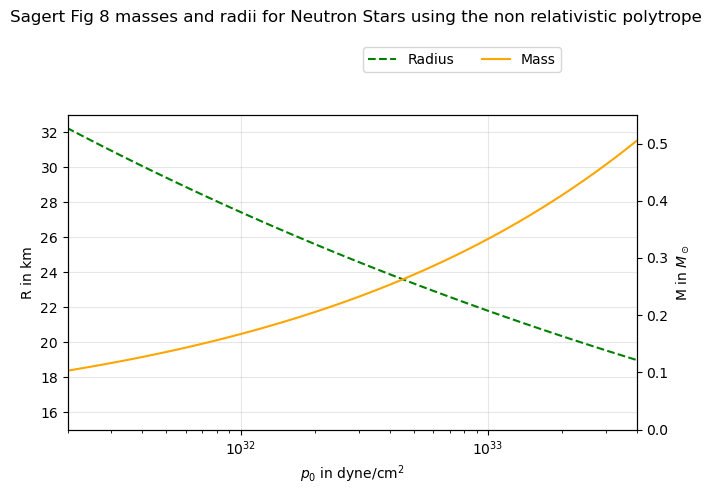

In [23]:
plot_sagert_8(central_pressures, radii, masses,
            'Sagert Fig 8 masses and radii for Neutron Stars using the non relativistic polytrope')

In [24]:
# Sagert Eq. (53): Tolman Oppenheimer Volkoff pressure gradient
# Extends Newtonian hydrostatic equilibrium with three relativistic corrections

def tov_pressure_gradient(r, epsilon, m, p):
    if epsilon <= 0:
        return 0.0

    newtonian = pressure_gradient(r, epsilon, m)

    factor_one = 1+(p)/(epsilon)
    factor_two = 1+(4*pi*r**3*p)/(m*c**2)
    factor_three = (1-(2*G*m)/(c**2*r))**(-1)

    return newtonian*factor_one*factor_two*factor_three

In [25]:
# Combine Sagert Eqs. (7) and (53) using the nonrelativistic neutron EOS
# Calculates the mass and TOV pressure gradients for the numerical solver
# Uses the same mass gradient and EOS as the Newtonian model
# Replaces Newtonian hydrostatic equilibrium with the relativistic TOV equation
# y: current state [m, p], containing enclosed mass (kg) and pressure (Pa)

def stellar_structure_tov(r, y, k_nrel, gamma):
    m, p = y

    epsilon = polytropic_energy_density(max(p, 0.0), k_nrel, gamma)

    dm_dr = mass_gradient(r, epsilon)
    dp_dr = tov_pressure_gradient(r, epsilon, m, p)

    return [dm_dr, dp_dr]

In [26]:
# Define a general TOV solver for the neutron polytropic model
# Calculates stellar mass and radius for any specified central pressure
# mirrors the same EOS and initial conditions as the Newtonian solver
# Integrates the TOV stellar structure equations until pressure reaches zero
# Checks that the stellar surface was successfully detected
# Returns R (stellar radius in metres) and M (gravitational mass in kg)

def solve_star_tov(p_c, k_nrel, gamma):

    r_c = 1.0
    y_c = initial_conditions(p_c, r_c, k_nrel, gamma)

    solution = solve_ivp(
        stellar_structure_tov,
        (r_c, 5e4),
        y_c,
      args=(k_nrel, gamma),
      events=stellar_surface,
      rtol=1e-10,
        atol=[1e12, 1e7]
          )
    if not solution.success or len(solution.t_events[0]) == 0:
        raise RuntimeError("Stellar surface was not found")
      
    R = solution.t_events[0][0]
    M = solution.y_events[0][0][0]
      
    return R, M

In [31]:
# test the TOV solver 

R_tov_test, M_tov_test = solve_star_tov(1e32, k_nrel, gamma)

print("Radius:", R_tov_test/1000, "km")
print("Mass:", M_tov_test/M_sun, "solar masses")

Radius: 21.205310439506736 km
Mass: 0.3055831496832993 solar masses


In [ ]:
# Calculate a sequence of TOV neutron star models
# Use the same central pressures and EOS as the Newtonian calculation
# Store the relativistic stellar radii and gravitational masses


radii_tov = []
masses_tov = []

for p_c in central_pressures:
    R, M = solve_star_tov(p_c, k_nrel, gamma)

    radii_tov.append(R / 1000)
    masses_tov.append(M / M_sun)

print("Calculated", len(masses_tov), "stellar models")

Calculated 70 stellar models


In [29]:
def plot_sagert_8_tov(central_pressures, radii, masses, radii_tov, masses_tov, title):
    pressures_plot = central_pressures * 10  # Pa to dyne/cm²

    fig, ax1 = plt.subplots(figsize=(7, 5))
    ax2 = ax1.twinx()
    ax1.set_xscale('log')

    ax1.set_xlim(2e31, 4e33)
    ax1.set_ylim(15, 33)
    ax1.set_yticks(np.arange(16, 33, 2))
        
    ax2.set_ylim(0, 0.55)
    ax2.set_yticks(np.arange(0, 0.51, 0.1))
    
    ax1.plot(
    pressures_plot,
    radii,
    color="brown",
    linestyle="--",
    label="Radius (Newton)")
    
    ax1.plot(
    pressures_plot,
    radii_tov,
    color="teal",
    linestyle="--",
    label="Radius (TOV)")
    
    ax2.plot(
    pressures_plot,
    masses_tov,
    color="purple",
    label=" Mass (TOV)")
    
    ax2.plot(
    pressures_plot,
    masses,
    color="pink",
    label=" Mass (Newton)")

    ax1.set_xlabel(r'$p_0$ in dyne/cm$^2$')
    ax1.set_ylabel('R in km')
    ax2.set_ylabel(r'M in $M_\odot$')
    fig.suptitle(title)
   
    ax2.ticklabel_format(axis='y', style='plain', useOffset=False)
    fig.legend(loc='upper center', bbox_to_anchor=(0.5, 0.92), ncol=4)
    ax1.grid(True, alpha=0.3)
    fig.tight_layout(rect=[0, 0, 1, 0.86])

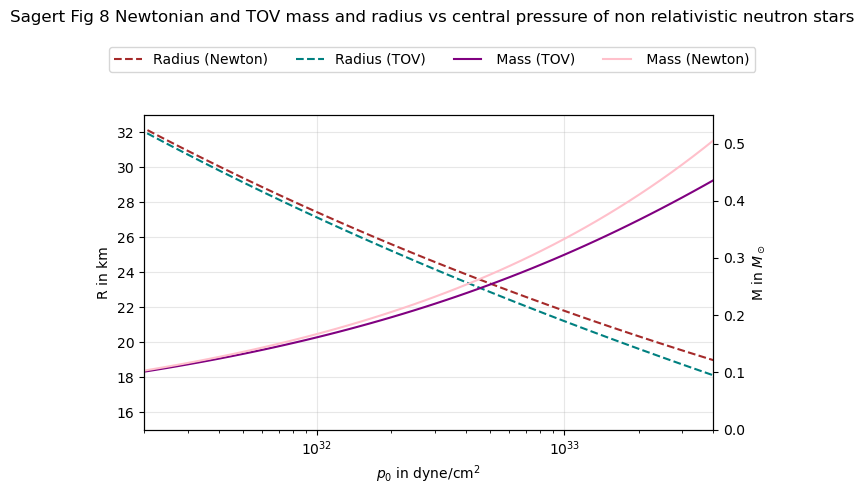

In [30]:
plot_sagert_8_tov(central_pressures, radii, masses, radii_tov, masses_tov, 
              "Sagert Fig 8 Newtonian and TOV mass and radius vs central pressure" \
              " of non relativistic neutron stars")